In [15]:
from google.colab import drive
drive.mount("/content/drive")

import yaml

import torch
import pandas as pd
import ultralytics
import shutil
from ultralytics import YOLO
from pathlib import Path

import random
import matplotlib.pyplot as plt
import cv2

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [10]:

DRIVE_ROOT = Path("/content/drive/MyDrive/CrackVision")
DATASET_DIR = DRIVE_ROOT / "data" / "crack-seg"
DATASET_YAML = DATASET_DIR / "crack-seg.yaml"

print("Dataset directory exists:", DATASET_DIR.exists())
print("Dataset YAML exists:", DATASET_YAML.exists())

if DATASET_DIR.exists():
    print("\nDataset contents:")
    for item in sorted(DATASET_DIR.iterdir()):
        print(item.name)


Dataset directory exists: True
Dataset YAML exists: True

Dataset contents:
crack-seg.yaml
images
labels


In [3]:
# Read the dataset YAML

with DATASET_YAML.open("r") as f:
  dataset_config = yaml.safe_load(f)

print("dataset configuration:")
print(dataset_config)


dataset configuration:
{'path': 'crack-seg', 'train': 'images/train', 'val': 'images/val', 'test': 'images/test', 'names': {0: 'crack'}, 'download': 'https://github.com/ultralytics/assets/releases/download/v0.0.0/crack-seg.zip'}


In [4]:
# Verify the dataset splits

for split in ("train", "val", "test"):
    image_dir = DATASET_DIR / "images" / split
    label_dir = DATASET_DIR / "labels" / split

    image_files = [
        p for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    ]
    label_files = list(label_dir.glob("*.txt"))

    print(
        f"{split:5} | "
        f"images: {len(image_files):4} | "
        f"label files: {len(label_files):4}"
    )


train | images: 3717 | label files: 3717
val   | images:  200 | label files:  200
test  | images:  112 | label files:  112


In [5]:
# check the dataset YAML paths

print("Dataset YAML:", DATASET_YAML)
print("\nConfigured paths:")

for key, value in dataset_config.items():
    print(f"{key}: {value}")

Dataset YAML: /content/drive/MyDrive/CrackVision/data/crack-seg/crack-seg.yaml

Configured paths:
path: crack-seg
train: images/train
val: images/val
test: images/test
names: {0: 'crack'}
download: https://github.com/ultralytics/assets/releases/download/v0.0.0/crack-seg.zip


In [6]:

%pip install -q ultralytics


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 24.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 10.3 MB/s eta 0:00:00


In [8]:
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

print("\nDataset YAML:", DATASET_YAML)
print("YAML exists:", DATASET_YAML.exists())

with DATASET_YAML.open("r") as f:
    config = yaml.safe_load(f)

print("\nDataset classes:", config.get("names"))
print("Number of classes:", config.get("nc"))
print("Configured train path:", config.get("train"))
print("Configured val path:", config.get("val"))


GPU available: True
GPU name: Tesla T4

Dataset YAML: /content/drive/MyDrive/CrackVision/data/crack-seg/crack-seg.yaml
YAML exists: True

Dataset classes: {0: 'crack'}
Number of classes: None
Configured train path: images/train
Configured val path: images/val


In [11]:
# 1. Confirm GPU access
if not torch.cuda.is_available():
    raise RuntimeError(
        "No GPU detected. In Colab, select Runtime > Change runtime type > GPU."
    )

print("GPU:", torch.cuda.get_device_name(0))

# 2. Verify the dataset in Google Drive
assert DATASET_DIR.exists(), f"Dataset not found: {DATASET_DIR}"
assert DATASET_YAML.exists(), f"YAML not found: {DATASET_YAML}"

# 3. Copy dataset to temporary Colab storage for faster access
LOCAL_DATASET_DIR = Path("/content/crack-seg")

if not LOCAL_DATASET_DIR.exists():
    shutil.copytree(DATASET_DIR, LOCAL_DATASET_DIR)

for split in ("train", "val", "test"):
    assert (LOCAL_DATASET_DIR / "images" / split).is_dir(), (
        f"Missing images/{split}"
    )
    assert (LOCAL_DATASET_DIR / "labels" / split).is_dir(), (
        f"Missing labels/{split}"
    )

# 4. Make a Colab-compatible dataset configuration
with DATASET_YAML.open("r") as f:
    config = yaml.safe_load(f)

config["path"] = str(LOCAL_DATASET_DIR)
config["train"] = "images/train"
config["val"] = "images/val"
config["test"] = "images/test"

LOCAL_YAML = Path("/content/crack-seg-colab.yaml")
with LOCAL_YAML.open("w") as f:
    yaml.safe_dump(config, f, sort_keys=False)

print("Dataset:", LOCAL_DATASET_DIR)
print("Classes:", config.get("names", config.get("nc")))
print("Dataset configuration ready.")

# 5. Train a small segmentation baseline
model = YOLO("yolo11n-seg.pt")

results = model.train(
    data=str(LOCAL_YAML),
    epochs=20,
    imgsz=640,
    batch=8,
    workers=2,
    device=0,
    patience=5,
    cache=False,
    project="/content/crackvision_runs",
    name="crack-seg-baseline",
    exist_ok=True,
    plots=True,
    seed=42,
)

# 6. Copy trained artifacts to persistent Google Drive storage
run_dir = Path(results.save_dir)
drive_run_dir = (
    Path("/content/drive/MyDrive/CrackVision")
    / "training-results"
    / "crack-seg-baseline"
)
drive_run_dir.mkdir(parents=True, exist_ok=True)

for filename in ("weights/best.pt", "weights/last.pt",
                 "results.csv", "results.png", "confusion_matrix.png"):
    source = run_dir / filename
    if source.is_file():
        destination = drive_run_dir / source.name
        shutil.copy2(source, destination)
        print("Saved:", destination)

print("\nTraining run finished.")
print("Run directory:", run_dir)
print("Persistent results:", drive_run_dir)

GPU: Tesla T4
Dataset: /content/crack-seg
Classes: {0: 'crack'}
Dataset configuration ready.
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/crack-seg-colab.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n-seg.pt, momentum=0.937

In [13]:
# Check the training results
run_dir = Path("/content/crackvision_runs/crack-seg-baseline")

print("Run directory exists:", run_dir.exists())

results_csv = run_dir / "results.csv"

if results_csv.exists():
    results = pd.read_csv(results_csv)
    results.columns = results.columns.str.strip()

    print("\nEpochs completed:", len(results))
    print("\nAvailable metrics:")
    print(results.columns.tolist())

    print("\nFinal training metrics:")
    display(results.tail(1).T)
else:
    print("results.csv not found in the expected location.")
    print("Check the run directory printed above.")


Run directory exists: True

Epochs completed: 20

Available metrics:
['epoch', 'time', 'train/box_loss', 'train/seg_loss', 'train/cls_loss', 'train/dfl_loss', 'train/sem_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'metrics/precision(M)', 'metrics/recall(M)', 'metrics/mAP50(M)', 'metrics/mAP50-95(M)', 'val/box_loss', 'val/seg_loss', 'val/cls_loss', 'val/dfl_loss', 'val/sem_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']

Final training metrics:


,19
epoch,20.000000
time,1727.310000
train/box_loss,0.741210
train/seg_loss,1.103220
train/cls_loss,0.745390
train/dfl_loss,1.119250
train/sem_loss,0.000000
metrics/precision(B),0.873580
metrics/recall(B),0.730920
metrics/mAP50(B),0.791360


In [14]:
# Check whether the model weights were saved
weights_dir = run_dir / "weights"

if weights_dir.exists():
    for weight_file in sorted(weights_dir.glob("*.pt")):
        print(f"{weight_file.name}: {weight_file.stat().st_size / (1024**2):.1f} MB")
else:
    print("Weights directory not found:", weights_dir)

drive_results = Path(
    "/content/drive/MyDrive/CrackVision/training-results/crack-seg-baseline"
)

print("\nGoogle Drive results folder exists:", drive_results.exists())

if drive_results.exists():
    for file in sorted(drive_results.rglob("*")):
        if file.is_file():
            print(file.relative_to(drive_results))


best.pt: 5.8 MB
last.pt: 5.8 MB

Google Drive results folder exists: True
best.pt
confusion_matrix.png
last.pt
results.csv
results.png


Results saved to /content/crackvision_runs/val_predictions


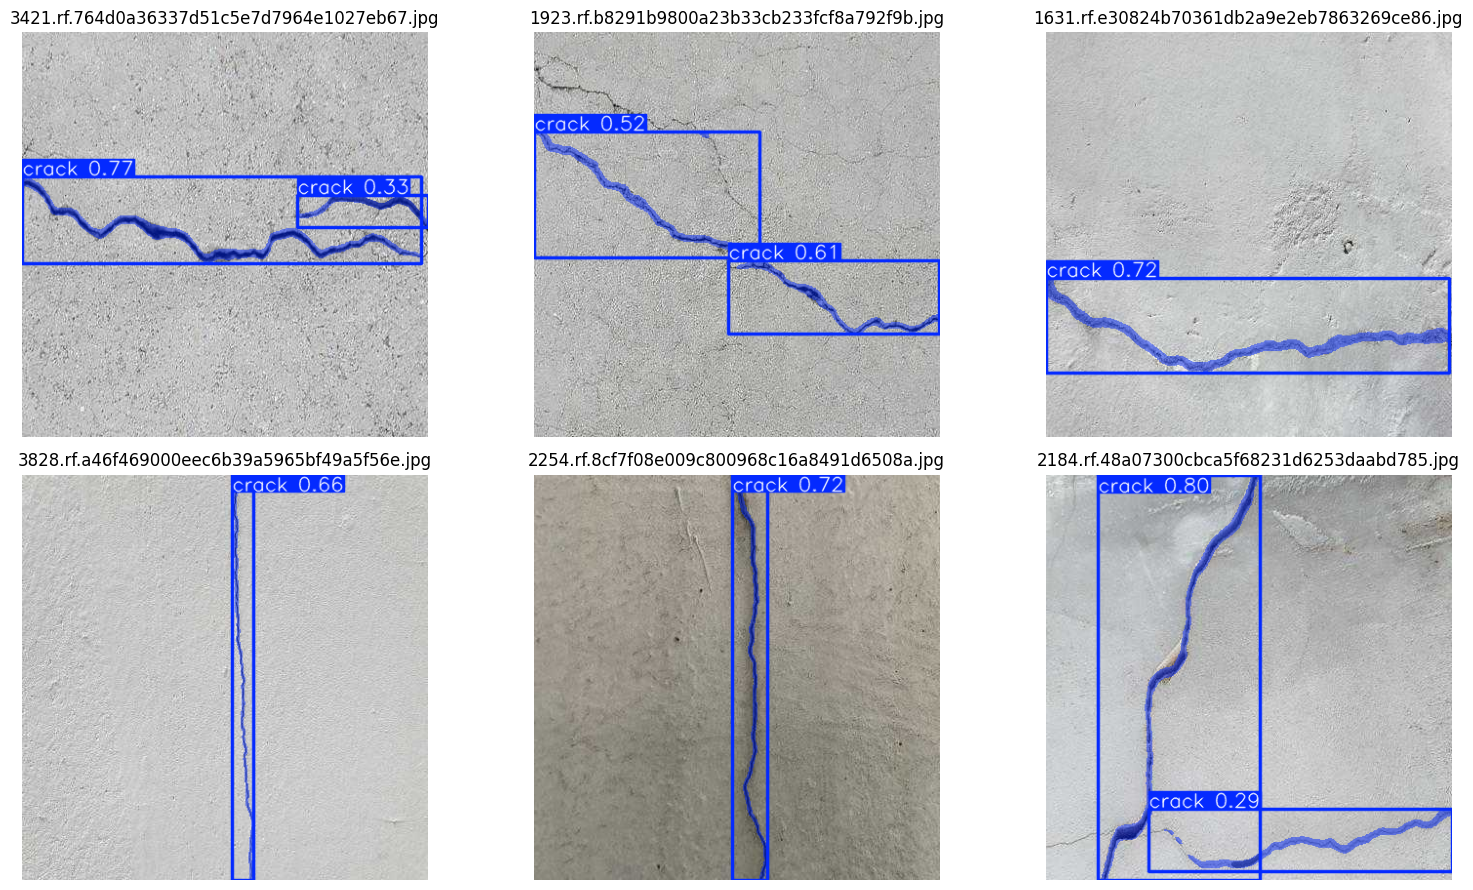

Predictions saved to: /content/crackvision_runs/val_predictions


In [16]:
# Load the best checkpoint saved in Google Drive
WEIGHTS_PATH = Path(
    "/content/drive/MyDrive/CrackVision/"
    "training-results/crack-seg-baseline/best.pt"
)

VAL_IMAGES_DIR = Path("/content/crack-seg/images/val")

assert WEIGHTS_PATH.exists(), f"Missing weights: {WEIGHTS_PATH}"
assert VAL_IMAGES_DIR.exists(), f"Missing validation images: {VAL_IMAGES_DIR}"

model = YOLO(str(WEIGHTS_PATH))

# Select up to six reproducible validation samples
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
val_images = sorted(
    p for p in VAL_IMAGES_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in image_extensions
)

assert val_images, "No validation images found."

rng = random.Random(42)
samples = rng.sample(val_images, min(6, len(val_images)))

# Predict crack masks
predictions = model.predict(
    source=[str(p) for p in samples],
    imgsz=640,
    conf=0.25,
    device=0,
    save=True,
    project="/content/crackvision_runs",
    name="val_predictions",
    exist_ok=True,
    verbose=False,
)

# Display images with predicted masks
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for ax, result in zip(axes, predictions):
    annotated_bgr = result.plot()
    annotated_rgb = cv2.cvtColor(annotated_bgr, cv2.COLOR_BGR2RGB)

    ax.imshow(annotated_rgb)
    ax.set_title(Path(result.path).name)
    ax.axis("off")

for ax in axes[len(predictions):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Predictions saved to:", predictions[0].save_dir)


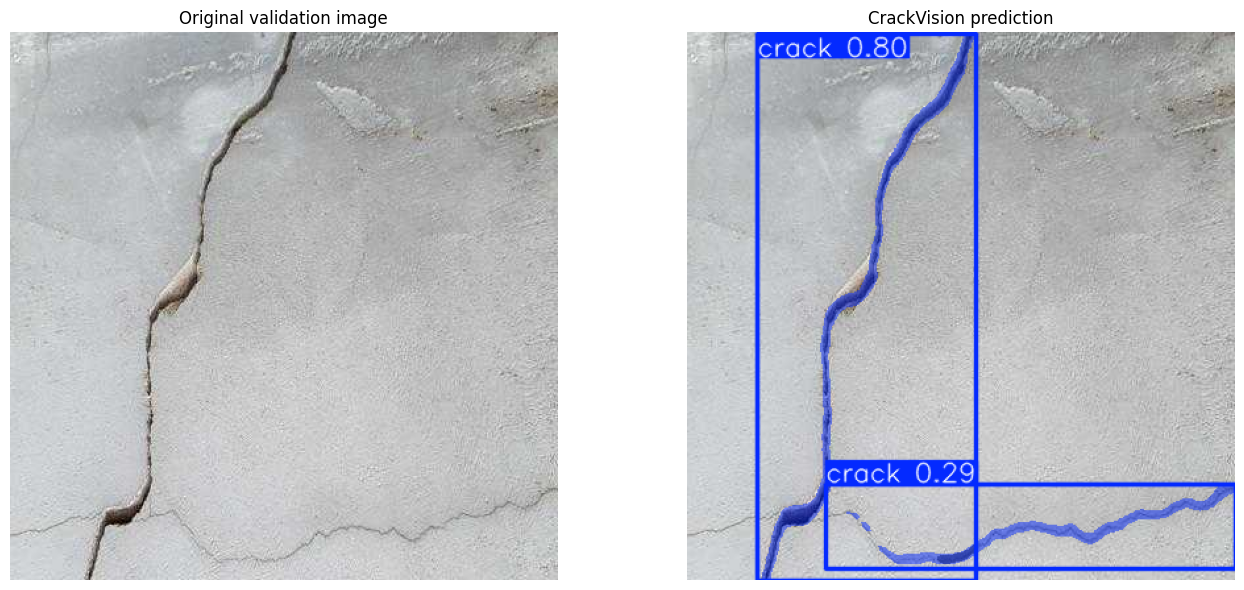

Ground-truth label exists: True
Ground-truth annotation:
0 0.513671875 0 0.5088114759615384 0.0004781418269230769 0.4979252043269231 0.02552368028846154 0.4870389350961538 0.05967668509615384 0.4742315576923077 0.09610655769230769 0.46142418028846155 0.11887522836538461 0.42492315625 0.15530510096153846 0.40763319711538465 0.17124316826923075 0.39738729567307696 0.18262750480769233 0.38586065625 0.20084243990384615 0.37625512259615385 0.22133424519230768 0.3672899591346154 0.23499544711538461 0.3570440576923077 0.2623178509615384 0.35128073798076925 0.2885018221153846 0.3480788942307692 0.3112704927884616 0.34551741826923077 0.3340391610576923 0.3448770480769231 0.35680783173076924 0.3423155745192308 0.37046903365384615 0.3397540985576923 0.39779143990384613 0.3352715168269231 0.42511384375000005 0.3275870913461538 0.4456056466346154 0.31413934374999997 0.46268214903846155 0.29941086057692307 0.4740664855769231 0.28532274519230766 0.4808970865384615 0.27635758173076924 0.48431238701923

In [17]:
# Compare predictions with ground-truth
# Load the best trained model
model = YOLO(
    "/content/drive/MyDrive/CrackVision/"
    "training-results/crack-seg-baseline/best.pt"
)

# Pick one validation image
image_path = Path(
    "/content/crack-seg/images/val/2184.rf.48a07300cbca5f68231d6253daabd785.jpg"
)

if not image_path.exists():
    raise FileNotFoundError(
        f"Image not found: {image_path}. "
        "Choose an existing image from VAL_IMAGES_DIR instead."
    )

# Find its ground-truth label
label_path = (
    Path("/content/crack-seg/labels/val")
    / f"{image_path.stem}.txt"
)

# Predict
result = model.predict(
    source=str(image_path),
    imgsz=640,
    conf=0.25,
    device=0,
    verbose=False
)[0]

# Original image
image = cv2.cvtColor(
    cv2.imread(str(image_path)),
    cv2.COLOR_BGR2RGB
)

# Predicted mask visualization
prediction_image = cv2.cvtColor(
    result.plot(),
    cv2.COLOR_BGR2RGB
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(image)
axes[0].set_title("Original validation image")
axes[1].imshow(prediction_image)
axes[1].set_title("CrackVision prediction")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Ground-truth label exists:", label_path.exists())
if label_path.exists():
    print("Ground-truth annotation:")
    print(label_path.read_text()[:1000])


In [18]:
# Evaluate the trained model
# Load the best checkpoint
WEIGHTS_PATH = Path(
    "/content/drive/MyDrive/CrackVision/"
    "training-results/crack-seg-baseline/best.pt"
)

# Load the dataset configuration
with open("/content/crack-seg-colab.yaml", "r") as f:
    config = yaml.safe_load(f)

# Verify test images and labels exist
test_images = Path("/content/crack-seg/images/test")
test_labels = Path("/content/crack-seg/labels/test")

assert WEIGHTS_PATH.exists(), f"Missing model weights: {WEIGHTS_PATH}"
assert test_images.is_dir(), f"Missing test images: {test_images}"
assert test_labels.is_dir(), f"Missing test labels: {test_labels}"

model = YOLO(str(WEIGHTS_PATH))

# Evaluate on the held-out test split
metrics = model.val(
    data="/content/crack-seg-colab.yaml",
    split="test",
    imgsz=640,
    batch=8,
    device=0,
    plots=True,
    project="/content/crackvision_runs",
    name="test-evaluation",
    exist_ok=True,
)

print("\nTest evaluation completed.")
print("Results saved to:", metrics.save_dir)


Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n-seg summary (fused): 114 layers, 2,849,467 parameters, 0 gradients, 9.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 600.9±569.0 MB/s, size: 16.0 KB)
val: Scanning /content/crack-seg/labels/test... 112 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 112/112 1.3Kit/s 0.1s
val: New cache created: /content/crack-seg/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 4.0it/s 3.5s
                   all        112        148      0.829      0.642      0.694      0.513      0.759      0.588        0.6      0.208
Speed: 3.3ms preprocess, 9.6ms inference, 0.0ms loss, 3.7ms postprocess per image
Results saved to /content/crackvision_runs/test-evaluation

Test evaluation completed.
Results saved to: /content/crackvision_runs/test-evaluation


In [19]:
# Preserve the test results
test_results = Path("/content/crackvision_runs/test-evaluation")
drive_test_results = Path(
    "/content/drive/MyDrive/CrackVision/evaluation-results/test-evaluation"
)

assert test_results.exists(), f"Results folder not found: {test_results}"

drive_test_results.mkdir(parents=True, exist_ok=True)

for item in test_results.iterdir():
    destination = drive_test_results / item.name

    if item.is_file():
        shutil.copy2(item, destination)
    elif item.is_dir():
        shutil.copytree(item, destination, dirs_exist_ok=True)

print("Test results copied to:", drive_test_results)
print("\nSaved files:")
for item in sorted(drive_test_results.rglob("*")):
    if item.is_file():
        print(item.relative_to(drive_test_results))


Test results copied to: /content/drive/MyDrive/CrackVision/evaluation-results/test-evaluation

Saved files:
BoxF1_curve.png
BoxPR_curve.png
BoxP_curve.png
BoxR_curve.png
MaskF1_curve.png
MaskPR_curve.png
MaskP_curve.png
MaskR_curve.png
confusion_matrix.png
confusion_matrix_normalized.png
val_batch0_labels.jpg
val_batch0_pred.jpg
val_batch1_labels.jpg
val_batch1_pred.jpg
val_batch2_labels.jpg
val_batch2_pred.jpg


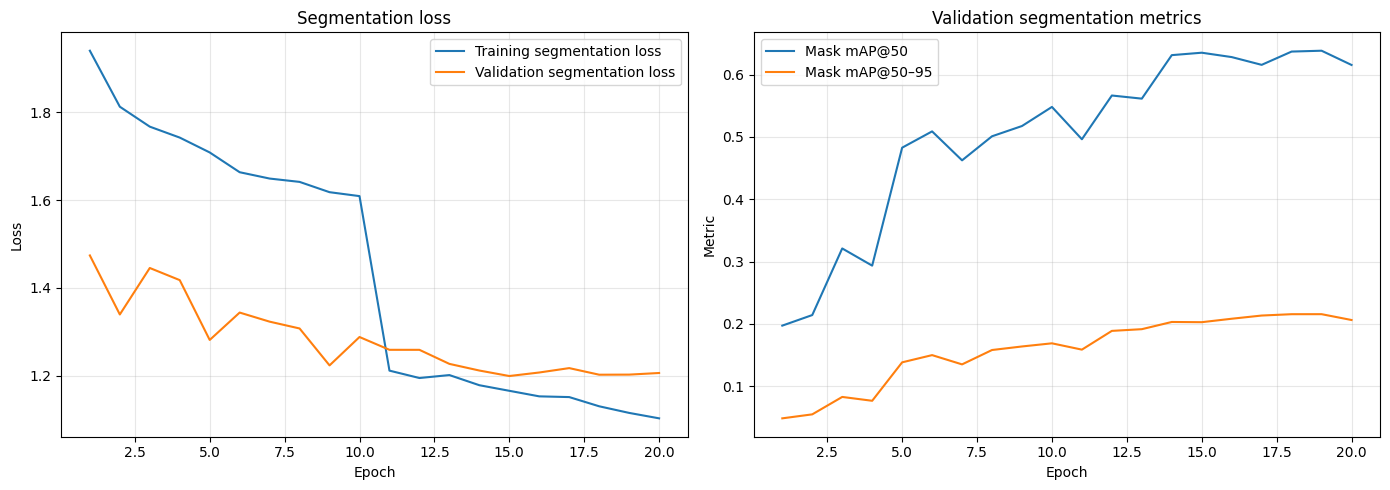

In [20]:
# Visualize the training curves
RUN_DIR = Path("/content/crackvision_runs/crack-seg-baseline")
RESULTS_CSV = RUN_DIR / "results.csv"

results = pd.read_csv(RESULTS_CSV)
results.columns = results.columns.str.strip()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Training and validation segmentation loss
axes[0].plot(results["epoch"], results["train/seg_loss"],
             label="Training segmentation loss")
axes[0].plot(results["epoch"], results["val/seg_loss"],
             label="Validation segmentation loss")
axes[0].set_title("Segmentation loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Mask evaluation metrics
axes[1].plot(results["epoch"], results["metrics/mAP50(M)"],
             label="Mask mAP@50")
axes[1].plot(results["epoch"], results["metrics/mAP50-95(M)"],
             label="Mask mAP@50–95")
axes[1].set_title("Validation segmentation metrics")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Metric")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [21]:
# finidng the best validation epoch

best_row = results.loc[results["metrics/mAP50-95(M)"].idxmax()]

print("Best epoch by mask mAP@50–95:")
print("Epoch:", int(best_row["epoch"]))
print("Mask mAP@50:", round(best_row["metrics/mAP50(M)"], 4))
print("Mask mAP@50–95:", round(best_row["metrics/mAP50-95(M)"], 4))

Best epoch by mask mAP@50–95:
Epoch: 19
Mask mAP@50: 0.6383
Mask mAP@50–95: 0.2156


In [22]:
# Preserve the best checkpoint and test results
drive_root = Path("/content/drive/MyDrive/CrackVision")
weights_dir = Path("/content/crackvision_runs/crack-seg-baseline/weights")

best_weights = weights_dir / "best.pt"
assert best_weights.exists(), f"Best checkpoint missing: {best_weights}"

# Preserve the checkpoint explicitly
final_model_dir = drive_root / "models"
final_model_dir.mkdir(parents=True, exist_ok=True)

final_model = final_model_dir / "crackvision-yolo11n-seg-best.pt"
shutil.copy2(best_weights, final_model)

print("Best checkpoint saved:", final_model)
print(f"Model size: {final_model.stat().st_size / (1024**2):.1f} MB")

# Check whether test evaluation artifacts exist
test_dir = drive_root / "evaluation-results" / "test-evaluation"

print("\nTest evaluation folder exists:", test_dir.exists())

if test_dir.exists():
    for item in sorted(test_dir.rglob("*")):
        if item.is_file():
            print(item.relative_to(test_dir))


Best checkpoint saved: /content/drive/MyDrive/CrackVision/models/crackvision-yolo11n-seg-best.pt
Model size: 5.8 MB

Test evaluation folder exists: True
BoxF1_curve.png
BoxPR_curve.png
BoxP_curve.png
BoxR_curve.png
MaskF1_curve.png
MaskPR_curve.png
MaskP_curve.png
MaskR_curve.png
confusion_matrix.png
confusion_matrix_normalized.png
val_batch0_labels.jpg
val_batch0_pred.jpg
val_batch1_labels.jpg
val_batch1_pred.jpg
val_batch2_labels.jpg
val_batch2_pred.jpg


In [23]:
DRIVE_ROOT = Path("/content/drive/MyDrive/CrackVision")
WEIGHTS_PATH = DRIVE_ROOT / "models" / "crackvision-yolo11n-seg-best.pt"
DATA_YAML = Path("/content/crack-seg-colab.yaml")

assert WEIGHTS_PATH.exists(), f"Model not found: {WEIGHTS_PATH}"
assert DATA_YAML.exists(), f"Dataset configuration not found: {DATA_YAML}"

with DATA_YAML.open("r") as f:
    config = yaml.safe_load(f)

print("Test images:", config.get("test"))
print("Dataset root:", config.get("path"))

model = YOLO(str(WEIGHTS_PATH))

metrics = model.val(
    data=str(DATA_YAML),
    split="test",
    imgsz=640,
    batch=8,
    device=0,
    plots=True,
    project="/content/crackvision_runs",
    name="test-evaluation",
    exist_ok=True,
)

print("\nTest evaluation complete.")

print("\nBounding-box metrics:")
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

print("\nSegmentation metrics:")
print("mAP50:", metrics.seg.map50)
print("mAP50-95:", metrics.seg.map)


Test images: images/test
Dataset root: /content/crack-seg
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n-seg summary (fused): 114 layers, 2,849,467 parameters, 0 gradients, 9.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1524.9±640.6 MB/s, size: 33.0 KB)
val: Scanning /content/crack-seg/labels/test.cache... 112 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 112/112 22.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 4.0it/s 3.5s
                   all        112        148      0.829      0.642      0.694      0.513      0.759      0.588        0.6      0.208
Speed: 3.8ms preprocess, 8.9ms inference, 0.0ms loss, 3.8ms postprocess per image
Results saved to /content/crackvision_runs/test-evaluation

Test evaluation complete.

Bounding-box metrics:
mAP50: 0.6937622844466502
mAP50-95: 0.5134146177298131

Seg

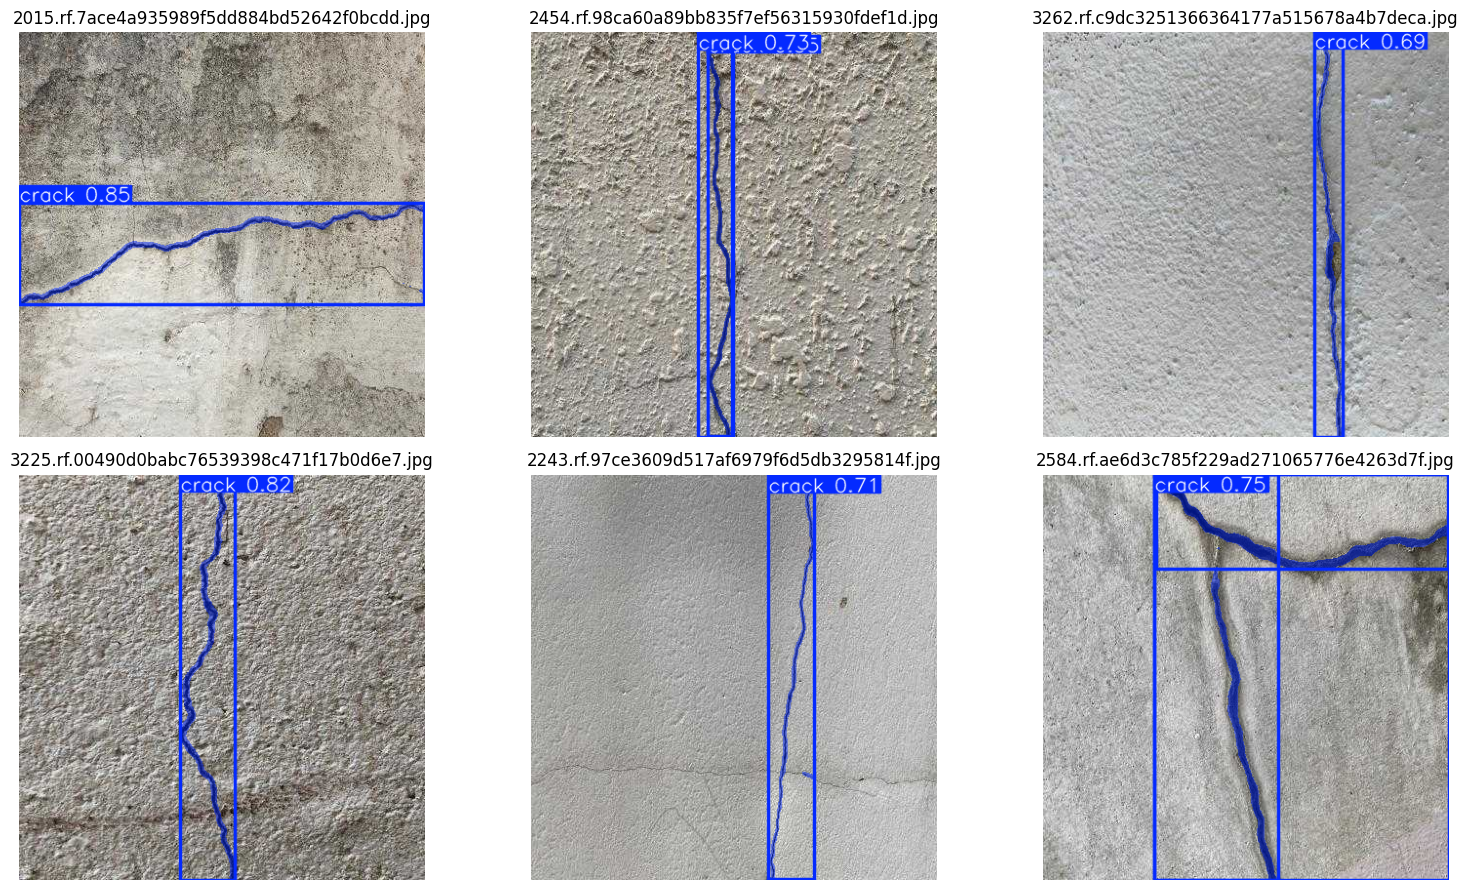

In [24]:
# Inspect test predictions visually
DRIVE_ROOT = Path("/content/drive/MyDrive/CrackVision")
WEIGHTS_PATH = DRIVE_ROOT / "models" / "crackvision-yolo11n-seg-best.pt"
TEST_IMAGES_DIR = Path("/content/crack-seg/images/test")

model = YOLO(str(WEIGHTS_PATH))

extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
test_images = sorted(
    p for p in TEST_IMAGES_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in extensions
)

rng = random.Random(21)
samples = rng.sample(test_images, min(6, len(test_images)))

predictions = model.predict(
    source=[str(p) for p in samples],
    imgsz=640,
    conf=0.25,
    device=0,
    verbose=False,
)

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for ax, result in zip(axes, predictions):
    annotated = cv2.cvtColor(result.plot(), cv2.COLOR_BGR2RGB)
    ax.imshow(annotated)
    ax.set_title(Path(result.path).name)
    ax.axis("off")

for ax in axes[len(predictions):]:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [25]:
# Preserve the test evaluation
SOURCE_DIR = Path("/content/crackvision_runs/test-evaluation")
DEST_DIR = Path(
    "/content/drive/MyDrive/CrackVision/evaluation-results/test-evaluation"
)

assert SOURCE_DIR.exists(), f"Evaluation results not found: {SOURCE_DIR}"

DEST_DIR.mkdir(parents=True, exist_ok=True)

for item in SOURCE_DIR.iterdir():
    destination = DEST_DIR / item.name

    if item.is_file():
        shutil.copy2(item, destination)
    elif item.is_dir():
        shutil.copytree(item, destination, dirs_exist_ok=True)

print("Test evaluation saved to Google Drive:")
print(DEST_DIR)

print("\nFiles saved:")
for item in sorted(DEST_DIR.rglob("*")):
    if item.is_file():
        print(f"{item.relative_to(DEST_DIR)} ({item.stat().st_size / 1024:.1f} KB)")


Test evaluation saved to Google Drive:
/content/drive/MyDrive/CrackVision/evaluation-results/test-evaluation

Files saved:
BoxF1_curve.png (107.3 KB)
BoxPR_curve.png (85.3 KB)
BoxP_curve.png (120.0 KB)
BoxR_curve.png (103.3 KB)
MaskF1_curve.png (105.7 KB)
MaskPR_curve.png (83.8 KB)
MaskP_curve.png (120.2 KB)
MaskR_curve.png (100.8 KB)
confusion_matrix.png (102.1 KB)
confusion_matrix_normalized.png (95.7 KB)
val_batch0_labels.jpg (692.0 KB)
val_batch0_pred.jpg (693.4 KB)
val_batch1_labels.jpg (541.5 KB)
val_batch1_pred.jpg (539.1 KB)
val_batch2_labels.jpg (699.0 KB)
val_batch2_pred.jpg (695.9 KB)


In [26]:
# Create a project results summary
test_summary = pd.DataFrame([{
    "model": "YOLO11n-seg",
    "training_epochs": 20,
    "test_images": 112,
    "box_precision": 0.829,
    "box_recall": 0.642,
    "box_mAP50": 0.694,
    "box_mAP50_95": 0.513,
    "mask_precision": 0.759,
    "mask_recall": 0.588,
    "mask_mAP50": 0.600,
    "mask_mAP50_95": 0.208,
}])

summary_path = (
    Path("/content/drive/MyDrive/CrackVision")
    / "evaluation-results"
    / "baseline_test_summary.csv"
)

summary_path.parent.mkdir(parents=True, exist_ok=True)
test_summary.to_csv(summary_path, index=False)

display(test_summary)
print("Summary saved to:", summary_path)


,model,training_epochs,test_images,box_precision,box_recall,box_mAP50,box_mAP50_95,mask_precision,mask_recall,mask_mAP50,mask_mAP50_95
0,YOLO11n-seg,20,112,0.829,0.642,0.694,0.513,0.759,0.588,0.6,0.208


Summary saved to: /content/drive/MyDrive/CrackVision/evaluation-results/baseline_test_summary.csv


In [29]:
DRIVE_ROOT = Path("/content/drive/MyDrive/CrackVision")
BASELINE_WEIGHTS = (
    DRIVE_ROOT / "models" / "crackvision-yolo11n-seg-best.pt"
)

assert BASELINE_WEIGHTS.exists(), f"Missing baseline weights: {BASELINE_WEIGHTS}"

# Start from the same pretrained-on-cracks baseline
model_highres = YOLO(str(BASELINE_WEIGHTS))

results_highres = model_highres.train(
    data="/content/crack-seg-colab.yaml",
    epochs=20,
    imgsz=960,
    batch=4,
    workers=2,
    device=0,
    patience=5,
    cache=False,
    project="/content/crackvision_runs",
    name="crack-seg-highres",
    exist_ok=True,
    plots=True,
    seed=42,
)

print("High-resolution experiment finished.")
print("Results directory:", results_highres.save_dir)


Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/crack-seg-colab.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyDrive/CrackVision/models/crackvision-yolo11n-seg-best.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, nam

In [30]:
# comparing both experiments
baseline_csv = Path(
    "/content/crackvision_runs/crack-seg-baseline/results.csv"
)
highres_csv = Path(
    "/content/crackvision_runs/crack-seg-highres/results.csv"
)

for path in (baseline_csv, highres_csv):
    assert path.exists(), f"Results file not found: {path}"

baseline = pd.read_csv(baseline_csv)
highres = pd.read_csv(highres_csv)

baseline.columns = baseline.columns.str.strip()
highres.columns = highres.columns.str.strip()

metric_cols = [
    "metrics/precision(M)",
    "metrics/recall(M)",
    "metrics/mAP50(M)",
    "metrics/mAP50-95(M)",
    "val/seg_loss",
]

# Compare each run's best validation epoch
baseline_best = baseline.loc[
    baseline["metrics/mAP50-95(M)"].idxmax()
]
highres_best = highres.loc[
    highres["metrics/mAP50-95(M)"].idxmax()
]

comparison = pd.DataFrame(
    {
        "Baseline (640)": baseline_best[metric_cols],
        "High resolution (960)": highres_best[metric_cols],
    }
)

print("Best validation epoch — baseline:", int(baseline_best["epoch"]))
print("Best validation epoch — high resolution:", int(highres_best["epoch"]))
display(comparison)


Best validation epoch — baseline: 19
Best validation epoch — high resolution: 18


,Baseline (640),High resolution (960)
metrics/precision(M),0.77626,0.73706
metrics/recall(M),0.59914,0.64257
metrics/mAP50(M),0.63827,0.61518
metrics/mAP50-95(M),0.21555,0.20312
val/seg_loss,1.20275,1.15802


In [31]:
# Save the second experiment result
drive_root = Path("/content/drive/MyDrive/CrackVision")
results_dir = Path("/content/crackvision_runs/crack-seg-highres")

destination = drive_root / "training-results" / "crack-seg-highres"
destination.mkdir(parents=True, exist_ok=True)

for filename in ("results.csv", "results.png"):
    source = results_dir / filename
    if source.exists():
        shutil.copy2(source, destination / filename)
        print("Saved:", destination / filename)

print("High-resolution experiment results preserved.")


Saved: /content/drive/MyDrive/CrackVision/training-results/crack-seg-highres/results.csv
Saved: /content/drive/MyDrive/CrackVision/training-results/crack-seg-highres/results.png
High-resolution experiment results preserved.


In [32]:
# Preseerve the high-resolution model
DRIVE_ROOT = Path("/content/drive/MyDrive/CrackVision")
HIGHRES_WEIGHTS = Path(
    "/content/crackvision_runs/crack-seg-highres/weights/best.pt"
)

assert HIGHRES_WEIGHTS.exists(), (
    f"Best high-resolution checkpoint not found: {HIGHRES_WEIGHTS}"
)

MODEL_DIR = DRIVE_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

DESTINATION = MODEL_DIR / "crackvision-yolo11n-seg-960-best.pt"
shutil.copy2(HIGHRES_WEIGHTS, DESTINATION)

print("Saved:", DESTINATION)
print(f"Size: {DESTINATION.stat().st_size / (1024**2):.1f} MB")


Saved: /content/drive/MyDrive/CrackVision/models/crackvision-yolo11n-seg-960-best.pt
Size: 5.8 MB


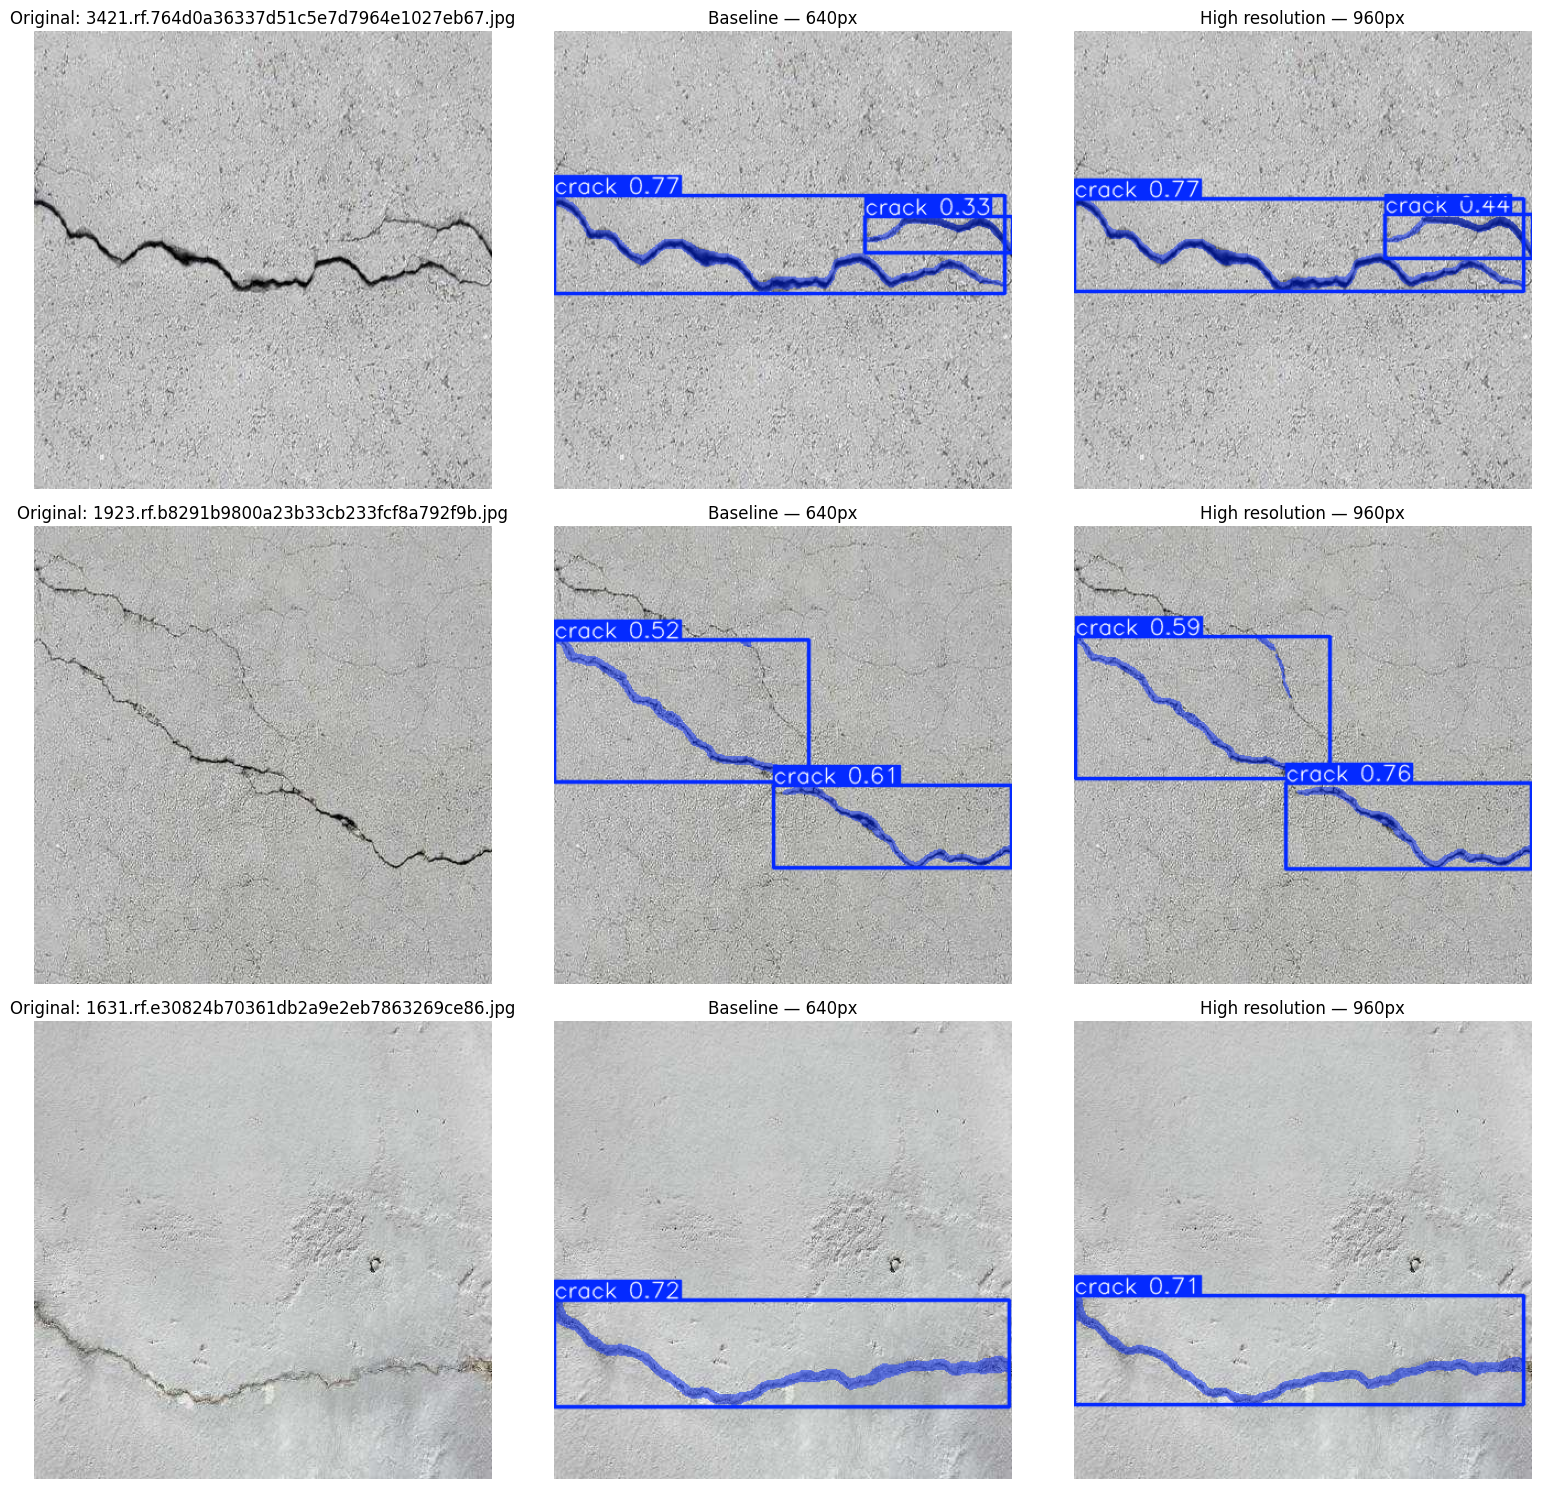

In [33]:
# Compare both models on the same validation images
DRIVE_ROOT = Path("/content/drive/MyDrive/CrackVision")
VAL_IMAGES_DIR = Path("/content/crack-seg/images/val")

baseline_path = (
    DRIVE_ROOT / "models" / "crackvision-yolo11n-seg-best.pt"
)
highres_path = (
    DRIVE_ROOT / "models" / "crackvision-yolo11n-seg-960-best.pt"
)

assert baseline_path.exists(), f"Missing baseline model: {baseline_path}"
assert highres_path.exists(), f"Missing high-resolution model: {highres_path}"

baseline_model = YOLO(str(baseline_path))
highres_model = YOLO(str(highres_path))

extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
val_images = sorted(
    p for p in VAL_IMAGES_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in extensions
)

rng = random.Random(42)
samples = rng.sample(val_images, min(3, len(val_images)))

fig, axes = plt.subplots(len(samples), 3, figsize=(16, 5 * len(samples)))
if len(samples) == 1:
    axes = axes.reshape(1, -1)

for row, image_path in enumerate(samples):
    original = cv2.cvtColor(
        cv2.imread(str(image_path)), cv2.COLOR_BGR2RGB
    )

    baseline_result = baseline_model.predict(
        str(image_path), imgsz=640, conf=0.25,
        device=0, verbose=False
    )[0]

    highres_result = highres_model.predict(
        str(image_path), imgsz=960, conf=0.25,
        device=0, verbose=False
    )[0]

    baseline_vis = cv2.cvtColor(
        baseline_result.plot(), cv2.COLOR_BGR2RGB
    )
    highres_vis = cv2.cvtColor(
        highres_result.plot(), cv2.COLOR_BGR2RGB
    )

    axes[row, 0].imshow(original)
    axes[row, 0].set_title(f"Original: {image_path.name}")
    axes[row, 1].imshow(baseline_vis)
    axes[row, 1].set_title("Baseline — 640px")
    axes[row, 2].imshow(highres_vis)
    axes[row, 2].set_title("High resolution — 960px")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()


# CrackVision — Model Training Summary

## Objective
Train a segmentation model to identify crack regions in surface images and produce pixel-level masks.

## Dataset
- Dataset: Crack-Seg
- Task: Single-class crack segmentation
- Training framework: Ultralytics YOLO
- Hardware: Google Colab GPU (Tesla T4)

## Experiment 1 — Baseline
- Model: YOLO11n-seg
- Input size: 640 × 640
- Training budget: 20 epochs
- Best validation epoch: 19
- Validation mask mAP@50: 63.83%
- Validation mask mAP@50–95: 21.56%
- Test mask mAP@50: 59.96%
- Test mask mAP@50–95: 20.76%

## Experiment 2 — Higher Resolution
- Starting checkpoint: baseline model's best weights
- Input size: 960 × 960
- Training budget: 20 epochs
- Best validation epoch: 18
- Validation mask mAP@50: 61.52%
- Validation mask mAP@50–95: 20.31%
- Validation mask recall: 64.26%

## Findings
The higher-resolution experiment improved validation recall but did not improve mask mAP. The 640-pixel baseline remains the stronger overall validation model under the metrics examined.

## Limitations
- The dataset contains one class: crack.
- The model does not classify crack orientation or severity.
- Pixel masks do not directly provide calibrated physical dimensions.
- Results do not establish structural safety or generalization to all surface types.

## Next Steps
1. Inspect prediction errors and mask boundaries.
2. Improve segmentation based on validation evidence.
3. Evaluate future model changes without repeatedly tuning on the test set.
4. Build camera inference after selecting a suitable model.
5. Add calibrated measurement only when a reliable scale reference is available.

In [34]:
# Verify that the project artifacts are present
ROOT = Path("/content/drive/MyDrive/CrackVision")

required_artifacts = [
    ROOT / "models" / "crackvision-yolo11n-seg-best.pt",
    ROOT / "models" / "crackvision-yolo11n-seg-960-best.pt",
    ROOT / "training-results" / "crack-seg-baseline" / "results.csv",
    ROOT / "training-results" / "crack-seg-highres" / "results.csv",
    ROOT / "evaluation-results" / "baseline_test_summary.csv",
]

for path in required_artifacts:
    status = "OK" if path.is_file() else "MISSING"
    print(f"[{status}] {path.relative_to(ROOT)}")


[OK] models/crackvision-yolo11n-seg-best.pt
[OK] models/crackvision-yolo11n-seg-960-best.pt
[OK] training-results/crack-seg-baseline/results.csv
[OK] training-results/crack-seg-highres/results.csv
[OK] evaluation-results/baseline_test_summary.csv


In [35]:
# Verify the saved artifacts
ROOT = Path("/content/drive/MyDrive/CrackVision")

artifacts = {
    "Baseline model": ROOT / "models/crackvision-yolo11n-seg-best.pt",
    "High-resolution model": ROOT / "models/crackvision-yolo11n-seg-960-best.pt",
    "Baseline training metrics": ROOT / "training-results/crack-seg-baseline/results.csv",
    "High-resolution training metrics": ROOT / "training-results/crack-seg-highres/results.csv",
    "Test summary": ROOT / "evaluation-results/baseline_test_summary.csv",
    "Test evaluation folder": ROOT / "evaluation-results/test-evaluation",
}

all_ok = True

for name, path in artifacts.items():
    exists = path.exists()
    print(f"[{'OK' if exists else 'MISSING'}] {name}: {path}")
    all_ok = all_ok and exists

print("\nAll required artifacts present:", all_ok)

[OK] Baseline model: /content/drive/MyDrive/CrackVision/models/crackvision-yolo11n-seg-best.pt
[OK] High-resolution model: /content/drive/MyDrive/CrackVision/models/crackvision-yolo11n-seg-960-best.pt
[OK] Baseline training metrics: /content/drive/MyDrive/CrackVision/training-results/crack-seg-baseline/results.csv
[OK] High-resolution training metrics: /content/drive/MyDrive/CrackVision/training-results/crack-seg-highres/results.csv
[OK] Test summary: /content/drive/MyDrive/CrackVision/evaluation-results/baseline_test_summary.csv
[OK] Test evaluation folder: /content/drive/MyDrive/CrackVision/evaluation-results/test-evaluation

All required artifacts present: True
